<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/05_brinson_performance_attribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🎯 Phase 5 — Brinson Performance Attribution

## Investment Objective

Evaluate the sources of benchmark-relative performance by
separating regional asset allocation, investment selection
and interaction effects.

### Methodology
- Brinson-Fachler attribution framework
- Portfolio and benchmark regional weights
- Regional benchmark returns
- Allocation, selection and interaction effects
- Multi-period attribution reconciliation

### Data
Historical regional ETF returns from the shared dataset,
combined with explicitly defined hypothetical benchmark
weights.

### Important Assumption
The attribution benchmark is a hypothetical regional
portfolio and is not equivalent to the Vanguard Total
World Stock ETF (VT).

### Expected Output
An investment attribution dashboard identifying the
regional decisions that contributed positively or
negatively to relative performance.


In [1]:

# ---------------------------------------------------------
# PHASE 5 - STEP 1: DEFINE ATTRIBUTION INPUTS
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load historical ETF prices from our shared GitHub dataset.
url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

prices = pd.read_csv(url, index_col="Date", parse_dates=["Date"])

# Calculate daily returns, then compound them by calendar year.
# These represent our regional BENCHMARK returns.
regional_benchmark_returns = (
    (1 + prices[["VTI", "VEA", "VWO"]].pct_change().dropna())
    .groupby(lambda date: date.year)
    .prod() - 1
)

# Define hypothetical portfolio and benchmark allocations.
# Both must sum to 100%.
portfolio_weights = pd.Series({
    "VTI": 0.60, "VEA": 0.30, "VWO": 0.10
})

benchmark_weights = pd.Series({
    "VTI": 0.65, "VEA": 0.25, "VWO": 0.10
})

assert np.isclose(portfolio_weights.sum(), 1)
assert np.isclose(benchmark_weights.sum(), 1)

# Introduce illustrative portfolio regional return differences
# to represent selection effects relative to regional benchmarks.
# These are assumptions, NOT observed manager alpha.
selection_assumptions = pd.Series({
    "VTI": 0.010,   # +1.0 percentage point
    "VEA": -0.005,  # -0.5 percentage points
    "VWO": 0.015    # +1.5 percentage points
})

portfolio_regional_returns = (
    regional_benchmark_returns + selection_assumptions
)

In [2]:

# ---------------------------------------------------------
# PHASE 5 - STEP 2: BRINSON-FACHLER ATTRIBUTION
# ---------------------------------------------------------

results = []

for year in regional_benchmark_returns.index:

    rb = regional_benchmark_returns.loc[year]
    rp = portfolio_regional_returns.loc[year]

    # Overall benchmark return.
    total_benchmark_return = benchmark_weights.dot(rb)

    # Allocation effect: active weight * regional benchmark
    # performance relative to the overall benchmark.
    allocation = (
        (portfolio_weights - benchmark_weights)
        * (rb - total_benchmark_return)
    )

    # Selection effect: benchmark weight * regional excess return.
    selection = benchmark_weights * (rp - rb)

    # Interaction: active weight * regional excess return.
    interaction = (
        (portfolio_weights - benchmark_weights)
        * (rp - rb)
    )

    # Total attribution by region.
    total = allocation + selection + interaction

    # Overall portfolio return.
    total_portfolio_return = portfolio_weights.dot(rp)

    # Reconciliation: total attribution must equal active return.
    assert np.isclose(
        total.sum(),
        total_portfolio_return - total_benchmark_return
    )

    # Store results in a structured table.
    for region in portfolio_weights.index:
        results.append({
            "Year": year,
            "Region": region,
            "Allocation": allocation[region],
            "Selection": selection[region],
            "Interaction": interaction[region],
            "Total": total[region]
        })

attribution = pd.DataFrame(results)

display(attribution.head(9))

,Year,Region,Allocation,Selection,Interaction,Total
0,2020,VTI,-0.001786,0.00650,-0.00050,0.004214
1,2020,VEA,-0.003841,-0.00125,-0.00025,-0.005341
2,2020,VWO,-0.000000,0.00150,0.00000,0.001500
3,2021,VTI,-0.002973,0.00650,-0.00050,0.003027
4,2021,VEA,-0.004036,-0.00125,-0.00025,-0.005536
5,2021,VWO,-0.000000,0.00150,0.00000,0.001500
6,2022,VTI,0.000600,0.00650,-0.00050,0.006600
7,2022,VEA,0.001491,-0.00125,-0.00025,-0.000009
8,2022,VWO,0.000000,0.00150,0.00000,0.001500


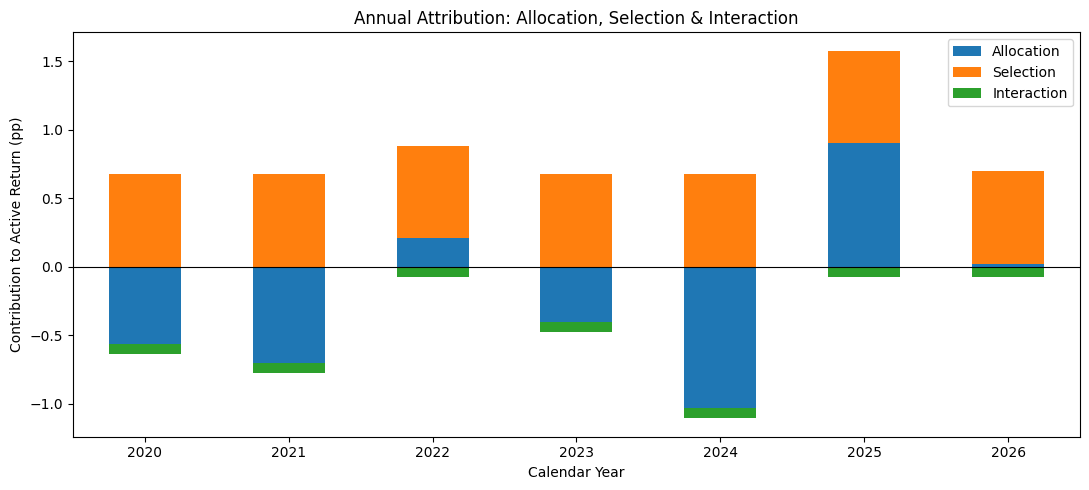

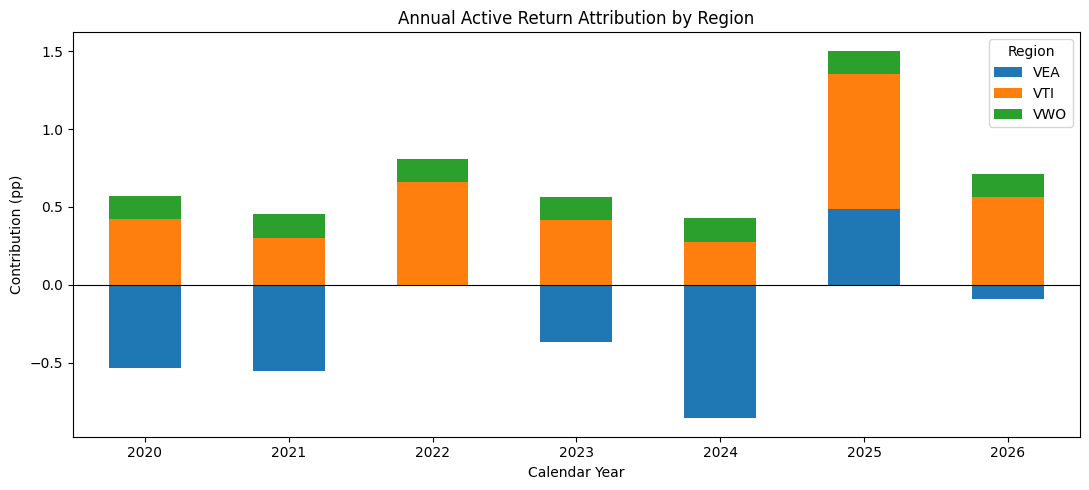

In [3]:

# ---------------------------------------------------------
# PHASE 5 - STEP 3: ATTRIBUTION VISUALISATIONS
# ---------------------------------------------------------

# Aggregate attribution effects by year.
annual_effects = (
    attribution.groupby("Year")[
        ["Allocation", "Selection", "Interaction"]
    ].sum() * 100
)

# Stacked bar chart showing annual attribution effects.
ax = annual_effects.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

ax.set_title("Annual Attribution: Allocation, Selection & Interaction")
ax.set_ylabel("Contribution to Active Return (pp)")
ax.set_xlabel("Calendar Year")
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Analyse each region's total contribution by year.
regional_effects = (
    attribution.pivot(
        index="Year",
        columns="Region",
        values="Total"
    ) * 100
)

ax = regional_effects.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5)
)

ax.set_title("Annual Active Return Attribution by Region")
ax.set_ylabel("Contribution (pp)")
ax.set_xlabel("Calendar Year")
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:

# ---------------------------------------------------------
# PHASE 5 - STEP 4: EXPORT ATTRIBUTION RESULTS
# ---------------------------------------------------------

# Export detailed regional attribution.
attribution.to_csv(
    "brinson_regional_attribution.csv",
    index=False
)

# Export annual attribution effects.
annual_effects.to_csv(
    "brinson_annual_effects.csv"
)

print("Attribution results exported successfully.")

Attribution results exported successfully.
